# DQN versus Double DQN on Pendulum

**Research question:** Under matched training and evaluation conditions, does the Double-DQN target improve discretised Pendulum control over ordinary DQN?

This compact notebook isolates the advanced target calculation and reproduces the tables and figure used in the Part C paper from exported experiment records. The complete training loop and weights are retained in the submitted Part B notebook and output folders.

In [1]:
from pathlib import Path
import os
os.environ['MPLCONFIGDIR'] = str((Path.cwd() / '.matplotlib').resolve())
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

ROOT = Path('.')
PAIRED = ROOT / 'Part_C_Double_DQN_Paired_Results.csv'
SUMMARY = ROOT / 'Part_C_Double_DQN_Summary.csv'

## Controlled configuration

Both methods used the same environment, network, action grid, replay settings, optimiser, exploration rate, target-copy interval, training budget and seed protocol. The target calculation was the only algorithmic change.

In [2]:
CONFIG = {
    'environment': 'Gym 0.17.3 Pendulum-v0',
    'gravity': 10.0,
    'hidden_units': [64, 64],
    'n_actions': 11,
    'episodes': 150,
    'max_steps': 200,
    'gamma': 0.99,
    'learning_rate': 5e-4,
    'batch_size': 64,
    'replay_capacity': 50_000,
    'warmup_steps': 1_000,
    'epsilon': 0.10,
    'target_update_steps': 500,
    'training_seeds': [17, 42, 73],
    'comparison_validation_seeds': list(range(11_000, 11_020)),
}
CONFIG

{'environment': 'Gym 0.17.3 Pendulum-v0',
 'gravity': 10.0,
 'hidden_units': [64, 64],
 'n_actions': 11,
 'episodes': 150,
 'max_steps': 200,
 'gamma': 0.99,
 'learning_rate': 0.0005,
 'batch_size': 64,
 'replay_capacity': 50000,
 'warmup_steps': 1000,
 'epsilon': 0.1,
 'target_update_steps': 500,
 'training_seeds': [17, 42, 73],
 'comparison_validation_seeds': [11000,
  11001,
  11002,
  11003,
  11004,
  11005,
  11006,
  11007,
  11008,
  11009,
  11010,
  11011,
  11012,
  11013,
  11014,
  11015,
  11016,
  11017,
  11018,
  11019]}

### Configuration output explained

The dictionary records the controls used by both candidates. Each run receives 30,000 environment interactions (`150 x 200`), uses the same two 64-unit hidden layers, 11 torque actions, replay and optimisation settings, and is evaluated on the same seed groups. Because these values are fixed, the target rule is the only intended model difference.

## Network architecture

The model accepts the three prepared Pendulum state values and returns one unrestricted Q-value for each of the 11 discrete torques. The target network has the same architecture and receives periodic copies of the online-network weights.

In [3]:
def build_q_network(n_actions=CONFIG['n_actions']):
    inputs = keras.Input(shape=(3,), name='state')
    x = keras.layers.Dense(64, activation='relu', name='hidden_1')(inputs)
    x = keras.layers.Dense(64, activation='relu', name='hidden_2')(x)
    outputs = keras.layers.Dense(n_actions, activation='linear', name='q_values')(x)
    return keras.Model(inputs, outputs, name='pendulum_q_network')

online_network = build_q_network()
target_network = build_q_network()
target_network.set_weights(online_network.get_weights())
architecture = pd.DataFrame([
    {'Layer': 'Input', 'Output shape': '(None, 3)', 'Parameters': 0},
    {'Layer': 'Dense ReLU 1', 'Output shape': '(None, 64)', 'Parameters': 256},
    {'Layer': 'Dense ReLU 2', 'Output shape': '(None, 64)', 'Parameters': 4160},
    {'Layer': 'Linear Q-values', 'Output shape': '(None, 11)', 'Parameters': 715},
])
assert online_network.count_params() == architecture['Parameters'].sum() == 5_131
display(architecture)
print('Total trainable parameters:', online_network.count_params())

             Layer Output shape  Parameters
0            Input    (None, 3)           0
1     Dense ReLU 1   (None, 64)         256
2     Dense ReLU 2   (None, 64)        4160
3  Linear Q-values   (None, 11)         715

Total trainable parameters: 5131


### Architecture output explained

The summary should show `3 -> 64 -> 64 -> 11` and 5,131 trainable parameters. The two hidden layers learn a nonlinear mapping from orientation and angular velocity to action values. The 11-unit linear output does not represent probabilities; each number estimates expected discounted return for one torque.

## State preparation and target equations

`cos(theta)` and `sin(theta)` are already in `[-1, 1]`. Angular velocity is divided by its environment bound of 8. Ordinary DQN lets the target network both select and evaluate the next action. Double DQN lets the online network select the action and the target network evaluate it.

In [4]:
ACTION_VALUES = np.linspace(-2.0, 2.0, CONFIG['n_actions'], dtype=np.float32)

def prepare_state(state):
    prepared = np.asarray(state, dtype=np.float32).copy()
    prepared[2] /= 8.0
    return prepared

def dqn_next_value(target_q):
    return np.max(target_q, axis=1)

def double_dqn_next_value(online_q, target_q):
    selected_actions = np.argmax(online_q, axis=1)
    return target_q[np.arange(len(selected_actions)), selected_actions]

example_online = np.array([[1.0, 3.0, 2.0], [4.0, 1.0, 0.0]])
example_target = np.array([[1.5, 2.5, 4.0], [2.0, 3.0, 1.0]])
assert np.allclose(dqn_next_value(example_target), [4.0, 3.0])
assert np.allclose(double_dqn_next_value(example_online, example_target), [2.5, 2.0])
action_table = pd.DataFrame({'Action index': np.arange(len(ACTION_VALUES)), 'Torque': ACTION_VALUES})
target_demo = pd.DataFrame({
    'DQN next value': dqn_next_value(example_target),
    'Double DQN selected action': np.argmax(example_online, axis=1),
    'Double DQN next value': double_dqn_next_value(example_online, example_target),
})
display(action_table)
display(target_demo)

    Action index  Torque
0              0    -2.0
1              1    -1.6
2              2    -1.2
3              3    -0.8
4              4    -0.4
5              5     0.0
6              6     0.4
7              7     0.8
8              8     1.2
9              9     1.6
10            10     2.0

   DQN next value  Double DQN selected action  Double DQN next value
0             4.0                           1                    2.5
1             3.0                           0                    2.0

### Action and target outputs explained

The first table confirms a symmetric action grid from `-2.0` to `2.0` with a step of `0.4`. The second table is an illustrative calculation, not an experimental result. DQN takes the largest target-network value directly (`4.0` and `3.0`). Double DQN first lets the online network select actions `1` and `0`, then reads those actions from the target network (`2.5` and `2.0`). This separation is the mechanism intended to reduce maximisation bias.

## Exported experiment evidence

A less negative reward is better. The paired difference is `Double DQN - DQN`, so positive values favour Double DQN.

In [5]:
paired = pd.read_csv(PAIRED)
summary = pd.read_csv(SUMMARY)
display(paired.round(2))
display(summary.round(4))

   training_seed  dqn_target  double_dqn_target  double_minus_dqn
0             17     -142.89            -185.16            -42.26
1             42     -146.85            -152.97             -6.13
2             73     -150.08            -148.04              2.05

       target  three_seed_mean  between_seed_std  mean_td_loss  \
0         DQN        -146.6083            3.6001        1.2494   
1  Double DQN        -162.0564           20.1597        1.3890   

   clipped_update_fraction  
0                   0.5978  
1                   0.6466  

### Experiment tables explained

The paired table compares the same training seeds. A positive `double_minus_dqn` favours Double DQN. Seed 73 improved by `2.05`, but seeds 17 and 42 declined by `42.26` and `6.13`. The summary table then combines the three trained policies: DQN has the better mean (`-146.61` versus `-162.06`) and much smaller between-seed spread (`3.60` versus `20.16`). Double DQN also has higher mean TD loss and more clipped updates, so its optimisation was not smoother in this run.

In [6]:
dqn_summary = summary.set_index('target').loc['DQN']
double_summary = summary.set_index('target').loc['Double DQN']
double_wins = int((paired['double_minus_dqn'] > 0).sum())
decision_rule_passed = bool(
    paired['double_dqn_target'].mean() > paired['dqn_target'].mean() and double_wins >= 2
)
checks = {
    'Double DQN seed wins': double_wins,
    'DQN mean reward': paired['dqn_target'].mean(),
    'Double DQN mean reward': paired['double_dqn_target'].mean(),
    'Mean difference': paired['double_minus_dqn'].mean(),
    'DQN between-seed SD': paired['dqn_target'].std(ddof=1),
    'Double DQN between-seed SD': paired['double_dqn_target'].std(ddof=1),
    'Spread multiplier': double_summary['between_seed_std'] / dqn_summary['between_seed_std'],
    'TD loss change': double_summary['mean_td_loss'] - dqn_summary['mean_td_loss'],
    'Clipped updates change (percentage points)': 100 * (double_summary['clipped_update_fraction'] - dqn_summary['clipped_update_fraction']),
    'Decision rule passed': decision_rule_passed,
}
rounded_checks = {
    key: round(float(value), 4) if isinstance(value, (float, np.floating)) else value
    for key, value in checks.items()
}
pd.Series(rounded_checks, name='Value').to_frame()

                                               Value
Double DQN seed wins                               1
DQN mean reward                            -146.6083
Double DQN mean reward                     -162.0564
Mean difference                              -15.448
DQN between-seed SD                           3.6001
Double DQN between-seed SD                   20.1597
Spread multiplier                             5.5998
TD loss change                                0.1396
Clipped updates change (percentage points)    4.8779
Decision rule passed                           False

### Calculated checks explained

The mean difference is about `-15.45` reward points, so Double DQN is worse on average. Its between-seed standard deviation is about `5.6` times DQN's. TD loss rises by about `0.140`, and clipping rises by about `4.88` percentage points. The decision rule is therefore `False`: Double DQN neither has a better mean nor wins at least two seeds. These are descriptive results; three training seeds are not enough for a broad statistical claim.

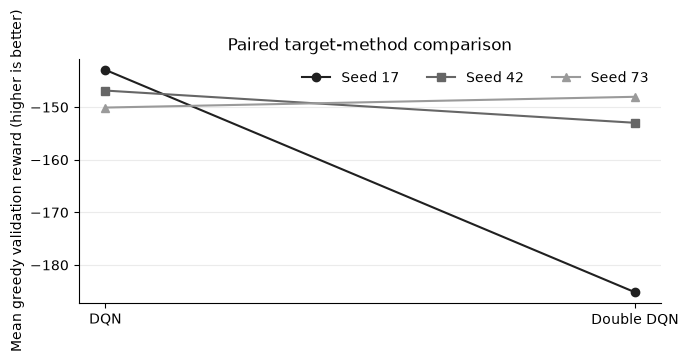

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for row, marker, shade in zip(paired.itertuples(index=False), ['o', 's', '^'], ['#202020', '#666666', '#9A9A9A']):
    ax.plot([0, 1], [row.dqn_target, row.double_dqn_target], marker=marker, color=shade, label=f'Seed {row.training_seed}')
ax.set_xticks([0, 1], ['DQN', 'Double DQN'])
ax.set_ylabel('Mean greedy validation reward (higher is better)')
ax.set_title('Paired target-method comparison')
ax.grid(axis='y', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

### Chart explained

Each line follows one independently trained policy from DQN to Double DQN. The line for seed 73 moves slightly upward, whereas seeds 17 and 42 move downward. Seed 17 accounts for the largest regression. DQN's three endpoints cluster tightly; Double DQN's endpoints are widely separated. The interesting finding is therefore increased seed sensitivity, not a claim that every Double-DQN run failed.

## Decision

Double DQN improved only seed 73. Its overall mean reward was lower and its between-seed spread was much larger. It therefore failed the pre-stated rule requiring a higher mean and improvement in at least two of three paired seeds. The correct conclusion is to retain ordinary DQN for this fixed-budget Pendulum configuration. This is an informative negative result, not a claim that Double DQN is generally worse. A stronger follow-up would add more seeds, a longer training budget and a direct comparison between predicted Q-values and empirical discounted returns.